# L1: Seasonality, Trend & Noise: Seeing the Structure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

# ---------- Helper: robust FRED-style CSV loader ----------
def load_fred_csv(path, value_name):
    """
    Works with FRED CSVs like CPIAUCSL.csv, UNRATE.csv.
    Normalizes columns, parses dates, returns a monthly DatetimeIndex series.
    """
    df = pd.read_csv(path)
    cols = [c.strip().upper() for c in df.columns]
    df.columns = cols

    # Heuristics to find date and value columns
    date_col = "DATE" if "DATE" in cols else cols[0]
    candidates = [c for c in cols if c != date_col]
    value_col = candidates[0]  # FRED usually has a single value column

    s = (df[[date_col, value_col]]
        .rename(columns={date_col: "date", value_col: value_name})
        .assign(date=lambda d: pd.to_datetime(d["date"]))
        .set_index("date")
        .sort_index()[value_name])

    # Force monthly frequency label when possible
    s = s.asfreq("MS") if s.index.inferred_freq in (None, "M", "MS") else s
    # Convert strings like "." to NaN and cast to float
    s = pd.to_numeric(s, errors="coerce")
    return s

# Load CPI (index level) and Unemployment rate (%)
cpi = load_fred_csv("data/CPIAUCSL.csv", "cpi")
unrate = load_fred_csv("data/UNRATE.csv", "unrate")

# Quick peek
display(cpi.head(), cpi.tail())
display(unrate.head(), unrate.tail())


date
1947-01-01    21.48
1947-02-01    21.62
1947-03-01    22.00
1947-04-01    22.00
1947-05-01    21.95
Freq: MS, Name: cpi, dtype: float64

date
2025-03-01    319.615
2025-04-01    320.321
2025-05-01    320.580
2025-06-01    321.500
2025-07-01    322.132
Freq: MS, Name: cpi, dtype: float64

date
1948-01-01    3.4
1948-02-01    3.8
1948-03-01    4.0
1948-04-01    3.9
1948-05-01    3.5
Freq: MS, Name: unrate, dtype: float64

date
2025-03-01    4.2
2025-04-01    4.2
2025-05-01    4.2
2025-06-01    4.1
2025-07-01    4.2
Freq: MS, Name: unrate, dtype: float64

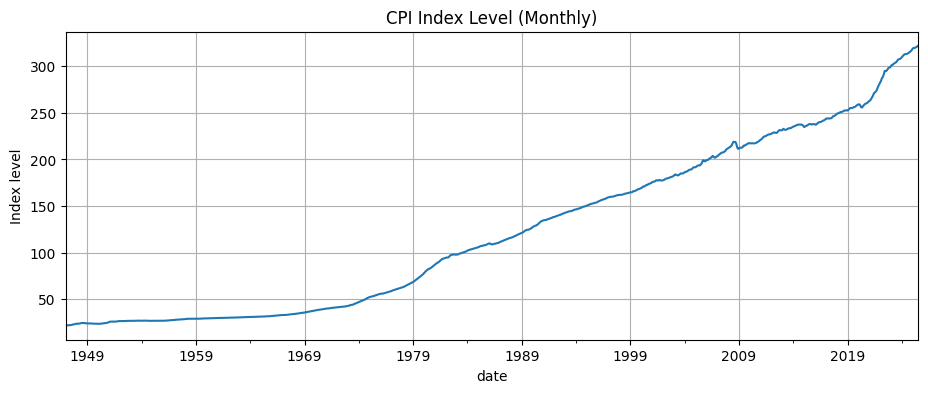

In [2]:
ax = cpi.plot(title="CPI Index Level (Monthly)")
ax.set_ylabel("Index level")
# ax.figure.savefig("L1_cpi_levels.png", dpi=150, bbox_inches="tight")  # <- save if needed
plt.show()


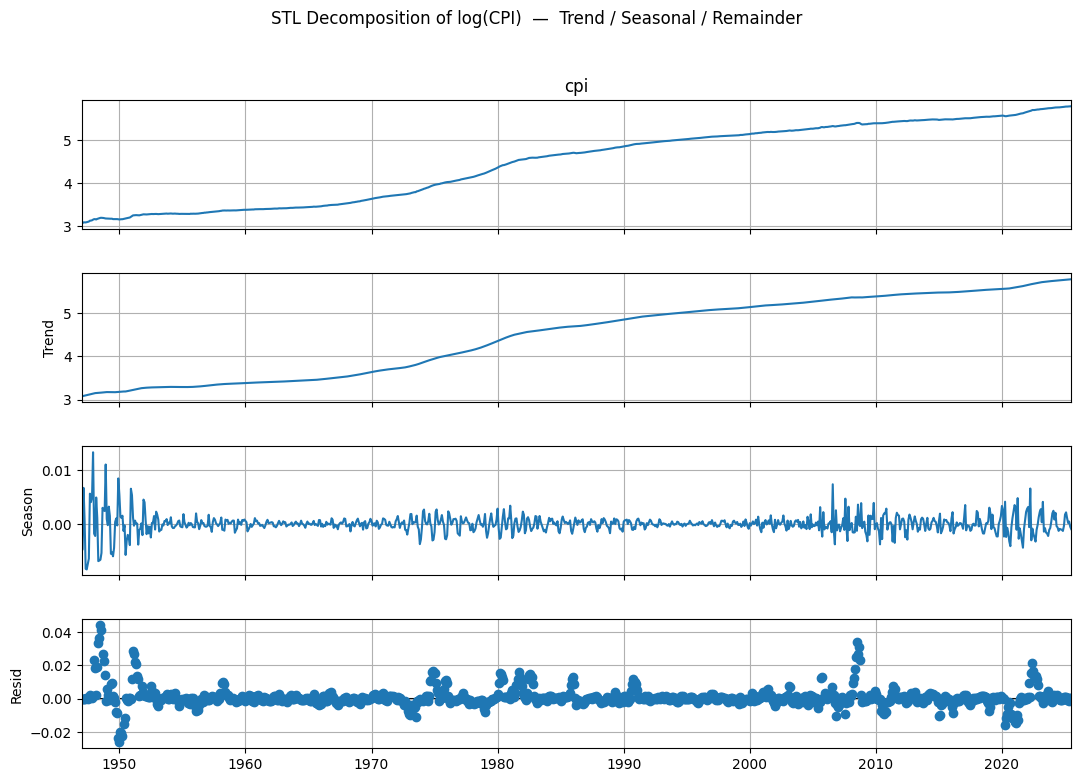

In [3]:
log_cpi = np.log(cpi)

# STL is robust and modern; set seasonal period m=12 for monthly data
stl = STL(log_cpi.dropna(), period=12, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(11, 8)
fig.suptitle("STL Decomposition of log(CPI)  —  Trend / Seasonal / Remainder", y=1.02)
# fig.savefig("L1_stl_logcpi.png", dpi=150, bbox_inches="tight")  # save if needed
plt.show()


In [4]:
def adf_kpss_report(x, name):
    x = x.dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(x, regression="c")  # 'c' = level stationarity
    print(f"{name:>15}  |  ADF p={adf_p:.4f} (H0: unit root)   |  KPSS p={kpss_p:.4f} (H0: stationary)")

adf_kpss_report(cpi,     "CPI (level)")
adf_kpss_report(log_cpi, "log(CPI)")


    CPI (level)  |  ADF p=0.9991 (H0: unit root)   |  KPSS p=0.0100 (H0: stationary)
       log(CPI)  |  ADF p=0.9371 (H0: unit root)   |  KPSS p=0.0100 (H0: stationary)


/var/folders/8f/j9bb2nzs27g8wwq5kb3dhkxm0000gn/T/ipykernel_20396/1767324808.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(x, regression="c")  # 'c' = level stationarity
/var/folders/8f/j9bb2nzs27g8wwq5kb3dhkxm0000gn/T/ipykernel_20396/1767324808.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(x, regression="c")  # 'c' = level stationarity


In [5]:
infl_mom = log_cpi.diff()  # d = 1
adf_kpss_report(infl_mom, "Δ log(CPI)  (≈ inflation m/m)")


Δ log(CPI)  (≈ inflation m/m)  |  ADF p=0.0001 (H0: unit root)   |  KPSS p=0.0482 (H0: stationary)


In [6]:
infl_mom_seas = infl_mom.diff(12)  # D = 1 with m = 12
adf_kpss_report(infl_mom_seas, "Δ log(CPI) & Δ12 (d=1, D=1)")


Δ log(CPI) & Δ12 (d=1, D=1)  |  ADF p=0.0000 (H0: unit root)   |  KPSS p=0.1000 (H0: stationary)


/var/folders/8f/j9bb2nzs27g8wwq5kb3dhkxm0000gn/T/ipykernel_20396/1767324808.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(x, regression="c")  # 'c' = level stationarity


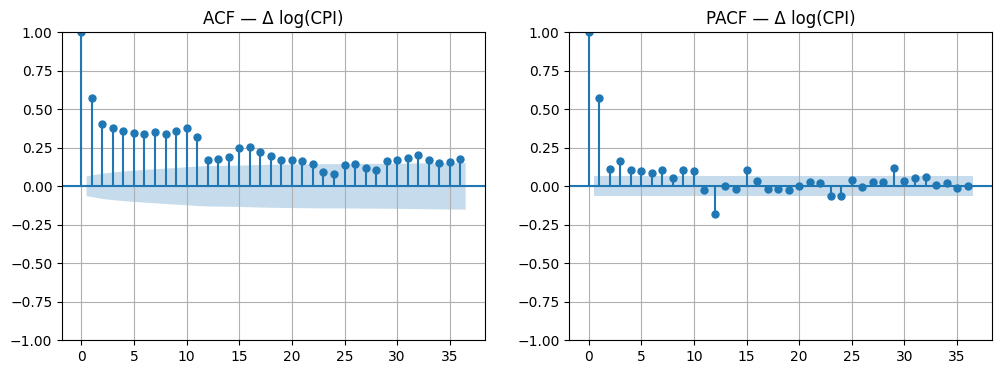

In [7]:
from matplotlib import pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(infl_mom.dropna(), lags=36, ax=axes[0])
plot_pacf(infl_mom.dropna(), lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF — Δ log(CPI)")
axes[1].set_title("PACF — Δ log(CPI)")
fig.savefig("L1_acf_pacf_infl_mom.png", dpi=150, bbox_inches="tight")  # save if needed
plt.show()


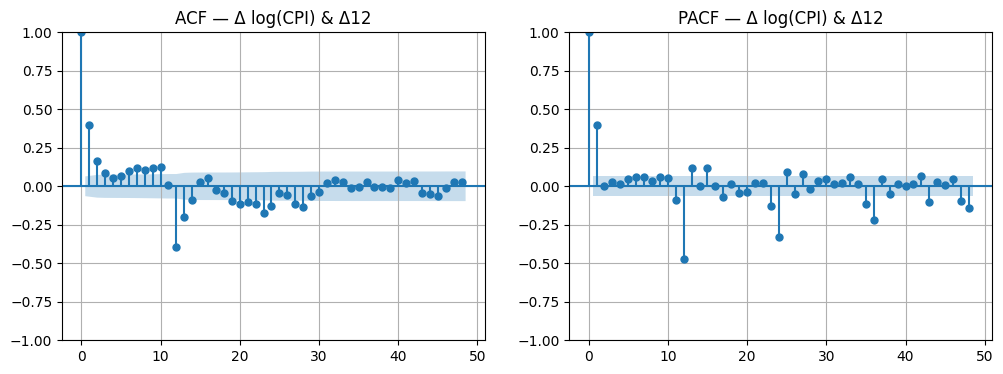

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(infl_mom_seas.dropna(), lags=48, ax=axes[0])
plot_pacf(infl_mom_seas.dropna(), lags=48, ax=axes[1], method="ywm")
axes[0].set_title("ACF — Δ log(CPI) & Δ12")
axes[1].set_title("PACF — Δ log(CPI) & Δ12")
plt.show()


TODO: Write down your choice and why (you’ll refer back to this when you fit ARIMA/SARIMA):
- Transformation: log vs. none? (CPI → log)
- d: first differencing? (CPI → yes, d=1)
- D: seasonal differencing? (often not required once you take ∆log for CPI, but check your ACF; if clear seasonal spikes remain, set D=1,m=12)
- Evidence: ADF/KPSS results + ACF/PACF behaviors.

Deliverable for your notebook: one markdown cell with a 4–6 sentence rationale for d,D,m supported by plots/tests.

In [9]:
un = unrate.copy()
adf_kpss_report(un, "UNRATE (level)")
un_diff = un.diff()
adf_kpss_report(un_diff, "Δ UNRATE")


 UNRATE (level)  |  ADF p=0.0018 (H0: unit root)   |  KPSS p=0.0718 (H0: stationary)
       Δ UNRATE  |  ADF p=0.0000 (H0: unit root)   |  KPSS p=0.1000 (H0: stationary)


/var/folders/8f/j9bb2nzs27g8wwq5kb3dhkxm0000gn/T/ipykernel_20396/1767324808.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(x, regression="c")  # 'c' = level stationarity


TODO: Reflection prompts (add to your notebook)
- After log and ∆, what’s left in the seasonal component from STL—does it look small or persistent?
- Do your tests agree (ADF & KPSS)? If not, which side do you trust and why?
- Compare ACF/PACF before vs. after differencing. What changed?
- If you tried both D=1, which produced cleaner residuals (less seasonal structure)?
- How would you explain your transformation & differencing choices to a non-technical stakeholder?


# L2: ARIMA Foundations

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

def load_fred_csv(path, value_name):
    df = pd.read_csv(path)
    cols = [c.strip().upper() for c in df.columns]
    df.columns = cols
    date_col = "DATE" if "DATE" in cols else cols[0]
    value_col = [c for c in cols if c != date_col][0]
    s = (df[[date_col, value_col]]
           .rename(columns={date_col: "date", value_col: value_name})
           .assign(date=lambda d: pd.to_datetime(d["date"]))
           .set_index("date")
           .sort_index()[value_name])
    s = pd.to_numeric(s, errors="coerce").asfreq("MS")
    return s

# Load CPI only for this lesson
cpi = load_fred_csv("data/CPIAUCSL.csv", "cpi")


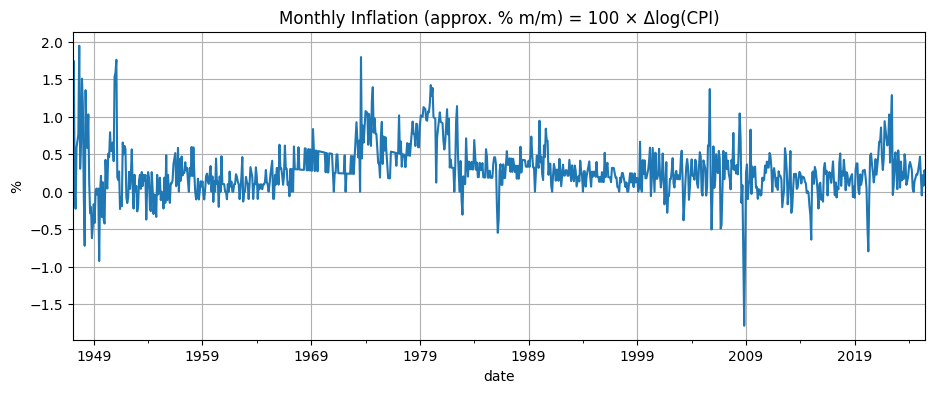

In [11]:
log_cpi = np.log(cpi)
y = log_cpi.diff().dropna()     # ← stationary target (d = 1 applied manually)
y.name = "inflation_mom"        # % m/m if multiplied by 100 later

# Quick visual
ax = (100*y).plot(title="Monthly Inflation (approx. % m/m) = 100 × Δlog(CPI)")
ax.set_ylabel("%")
# ax.figure.savefig("L2_inflation_mom.png", dpi=150, bbox_inches="tight")
plt.show()


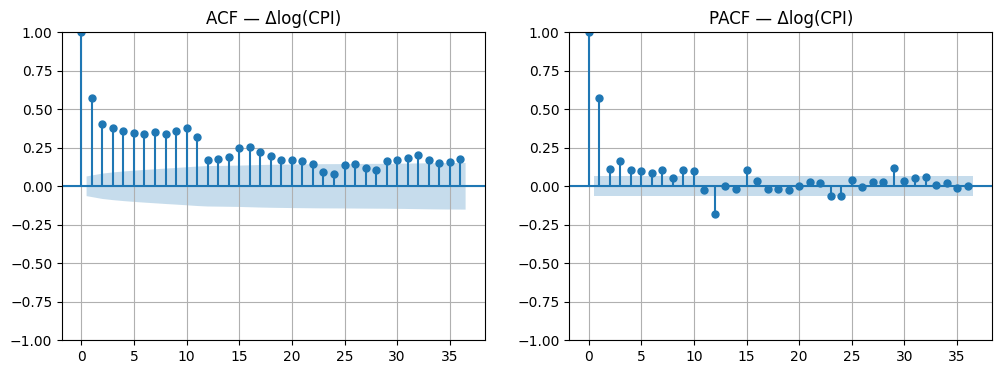

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
plot_acf(y, lags=36, ax=axes[0]); axes[0].set_title("ACF — Δlog(CPI)")
plot_pacf(y, lags=36, ax=axes[1], method="ywm"); axes[1].set_title("PACF — Δlog(CPI)")
# fig.savefig("L2_acf_pacf_inflation.png", dpi=150, bbox_inches="tight")
plt.show()


In [13]:
candidates = [(p,q) for p in range(0,7) for q in range(0,4)]
rows = []
fits = {}

for p,q in candidates:
    try:
        mod = SARIMAX(y, order=(p,0,q), enforce_stationarity=True, enforce_invertibility=True)
        res = mod.fit(disp=False)
        fits[(p,q)] = res
        rows.append({"p":p, "q":q, "AIC":res.aic, "BIC":res.bic})
    except Exception as e:
        # Some combos may not converge; skip them
        continue

order_tbl = (pd.DataFrame(rows)
               .sort_values(["AIC","BIC"])
               .reset_index(drop=True))
order_tbl.head(10)


/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check ml

,p,q,AIC,BIC
0,2,3,-8466.766578,-8437.678546
1,1,3,-8464.588443,-8440.348417
2,3,3,-8464.429932,-8430.493895
3,4,3,-8462.834216,-8424.050174
4,3,2,-8461.893530,-8432.805499
5,1,2,-8459.984918,-8440.592897
6,2,1,-8459.485700,-8440.093679
7,2,2,-8457.024095,-8432.784069
8,4,2,-8456.855032,-8422.918995
9,5,2,-8455.837918,-8417.053876


In [14]:
best_p, best_q = int(order_tbl.iloc[0]["p"]), int(order_tbl.iloc[0]["q"])
best_res = fits[(best_p, best_q)]
print(f"Chosen ARMA order on Δlog(CPI): p={best_p}, q={best_q}")
best_res.summary()


Chosen ARMA order on Δlog(CPI): p=2, q=3


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:          inflation_mom   No. Observations:                  942
Model:               SARIMAX(2, 0, 3)   Log Likelihood                4239.383
Date:                Tue, 10 Feb 2026   AIC                          -8466.767
Time:                        14:16:20   BIC                          -8437.679
Sample:                    02-01-1947   HQIC                         -8455.679
                         - 07-01-2025                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3787      0.008     46.408      0.000       0.363       0.395
ar.L2          0.6023      0.007     84.283      0.000       0.588       0.616
ma.L1          0.0723      0.012      5.880      0.000       0.048       0.096
ma.L2         -0.5836      0.019    -29.944      0.000      -0.622      -0.545
ma.L3         -0.1540      0.023     -6.751      0.000      -0.199      -0.109
sigma2      7.182e-06   1.73e-07     41.439      0.000    6.84e-06    7.52e-06
===================================================================================
Ljung-Box (L1) (Q):                   0.06   Jarque-Bera (JB):              1179.30
Prob(Q):                              0.81   Prob(JB):                         0.00
Heteroskedasticity (H):               0.76   Skew:                            -0.11
Prob(H) (two-sided):                  0.02   Kurtosis:                         8.48
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 2.41e+16. Standard errors may be unstable.
"""

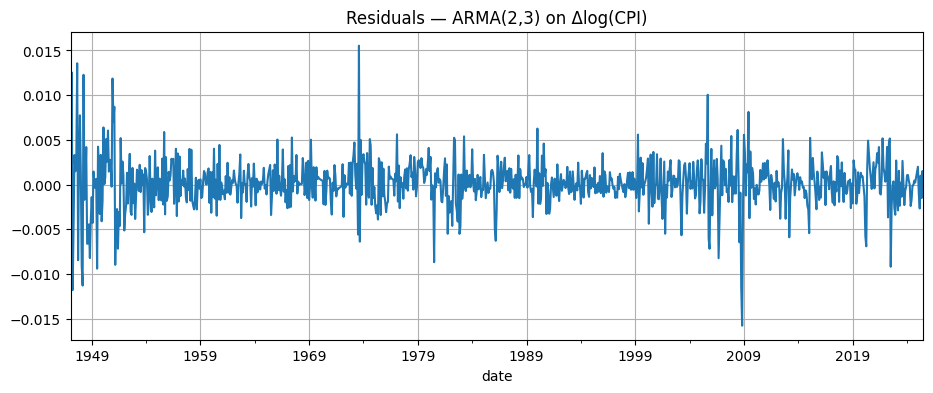

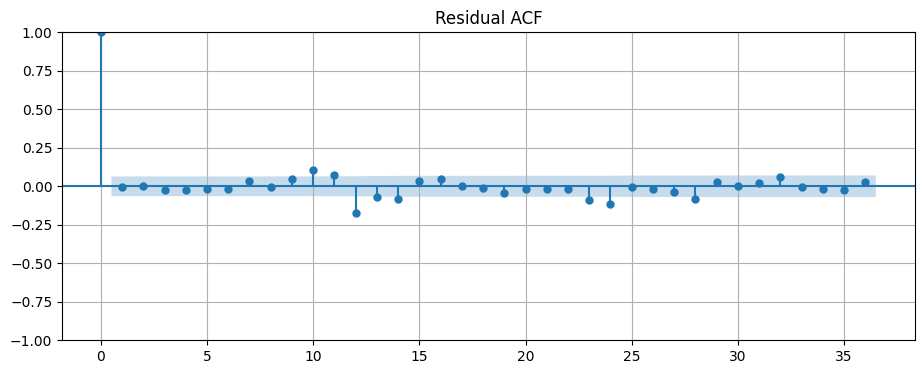

,lb_stat,lb_pvalue
12,50.787969,1.015249e-06
24,87.723040,3.421816e-09


In [15]:
resid = best_res.resid.dropna()

fig, ax = plt.subplots()
resid.plot(ax=ax, title=f"Residuals — ARMA({best_p},{best_q}) on Δlog(CPI)")
# fig.savefig("L2_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots()
plot_acf(resid, lags=36, ax=ax); ax.set_title("Residual ACF")
# fig.savefig("L2_resid_acf.png", dpi=150, bbox_inches="tight")
plt.show()

lb = acorr_ljungbox(resid, lags=[12,24], return_df=True)
lb


In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(resid, lags=[12, 24, 36], return_df=True)
print(lb)


       lb_stat     lb_pvalue
12   50.787969  1.015249e-06
24   87.723040  3.421816e-09
36  102.183474  2.964194e-08


In [29]:
h = 60
y_train, y_test = y.iloc[:-h], y.iloc[-h:]

# Refit on train only
res_train = SARIMAX(y_train, order=(best_p,0,best_q),
                    enforce_stationarity=True, enforce_invertibility=True).fit(disp=False)

# One-step-ahead on the test window (uses actuals each step)
pred_1 = res_train.get_prediction(start=y_test.index[0], end=y_test.index[-1], dynamic=False)
mean_1 = pred_1.predicted_mean
ci_1 = pred_1.conf_int()

# Dynamic multi-step (true recursion after the first step)
pred_dyn = res_train.get_prediction(start=y_test.index[0], end=y_test.index[-1], dynamic=True)
mean_dyn = pred_dyn.predicted_mean
ci_dyn = pred_dyn.conf_int()

mae_1  = mean_absolute_error(y_test, mean_1)
mae_d  = mean_absolute_error(y_test, mean_dyn)

rmse_1 = np.sqrt(mean_squared_error(y_test, mean_1))
rmse_d = np.sqrt(mean_squared_error(y_test, mean_dyn))


mae_1, rmse_1, mae_d, rmse_d


(0.0029908597573959713,
 np.float64(0.003925273438322979),
 0.0029908597573959713,
 np.float64(0.003925273438322979))

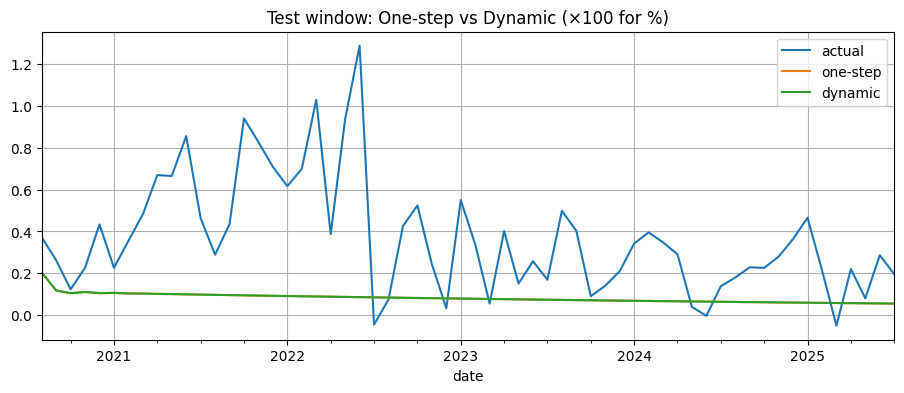

One-step  MAE=0.299  RMSE=0.393  (basis points)
Dynamic   MAE=0.299  RMSE=0.393  (basis points)


In [30]:
ax = (100*y_test).plot(label="actual", title=f"Test window: One-step vs Dynamic (×100 for %)")
(100*mean_1).plot(ax=ax, label="one-step")
(100*mean_dyn).plot(ax=ax, label="dynamic")
plt.legend()
# ax.figure.savefig("L2_test_onestep_vs_dynamic.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"One-step  MAE={100*mae_1:.3f}  RMSE={100*rmse_1:.3f}  (basis points)")
print(f"Dynamic   MAE={100*mae_d:.3f}  RMSE={100*rmse_d:.3f}  (basis points)")


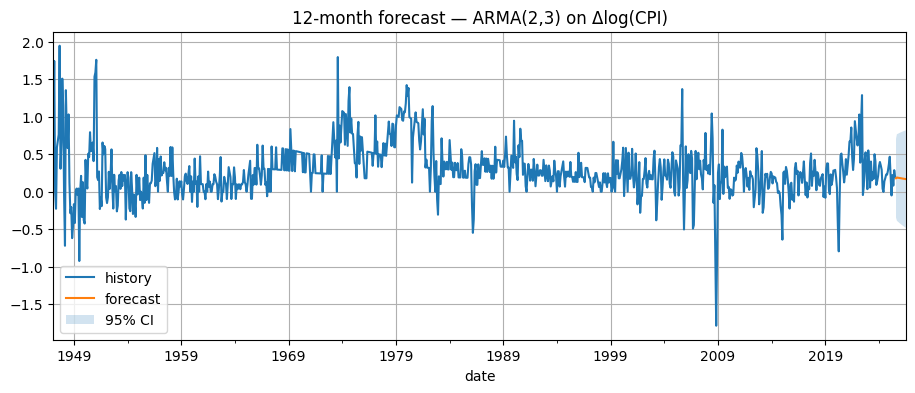

In [31]:
final_res = SARIMAX(y, order=(best_p,0,best_q),
                    enforce_stationarity=True, enforce_invertibility=True).fit(disp=False)

fc = final_res.get_forecast(steps=12)
fc_mean = fc.predicted_mean
fc_ci = fc.conf_int()

ax = (100*y).plot(label="history", title=f"12-month forecast — ARMA({best_p},{best_q}) on Δlog(CPI)")
(100*fc_mean).plot(ax=ax, label="forecast")
ax.fill_between(fc_ci.index, 100*fc_ci.iloc[:,0], 100*fc_ci.iloc[:,1], alpha=0.2, label="95% CI")
plt.legend()
# ax.figure.savefig("L2_12m_fc.png", dpi=150, bbox_inches="tight")
plt.show()


TODO: Reflection & critical thinking
Add short answers to your notebook:
- ACF/PACF → orders: What features in your ACF/PACF justified your (p,q) choice?
- Diagnostics: Do residuals look like white noise? If not, which lag(s) misbehave?
- Forecast realism: Does your dynamic forecast look nearly flat? If yes, why is that correct for this series?
- Next improvements (teaser for L3): Do you see hints of seasonality (lag ~12) in ACF? If yes, plan to test SARIMA next.

In [32]:
# Equivalent: fit ARIMA(p,1,q) on log-levels (no manual differencing)
res_arima = SARIMAX(log_cpi.dropna(),
                    order=(best_p,1,best_q),
                    enforce_stationarity=True,
                    enforce_invertibility=True).fit(disp=False)
res_arima.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                    cpi   No. Observations:                  943
Model:               SARIMAX(2, 1, 3)   Log Likelihood                4238.985
Date:                Tue, 10 Feb 2026   AIC                          -8465.970
Time:                        14:24:16   BIC                          -8436.882
Sample:                    01-01-1947   HQIC                         -8454.882
                         - 07-01-2025                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3819      1.895      0.202      0.840      -3.332       4.096
ar.L2          0.5990      1.873      0.320      0.749      -3.073       4.271
ma.L1          0.0703      1.895      0.037      0.970      -3.645       3.785
ma.L2         -0.5644      1.010     -0.559      0.576      -2.543       1.415
ma.L3         -0.1374      0.461     -0.298      0.766      -1.042       0.767
sigma2      7.211e-06   1.75e-07     41.189      0.000    6.87e-06    7.55e-06
===================================================================================
Ljung-Box (L1) (Q):                   0.05   Jarque-Bera (JB):              1166.37
Prob(Q):                              0.83   Prob(JB):                         0.00
Heteroskedasticity (H):               0.77   Skew:                            -0.14
Prob(H) (two-sided):                  0.02   Kurtosis:                         8.44
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

# L3: Seasonal ARIMA (SARIMA): When Patterns Repeat Every Year

In [33]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


In [34]:
def load_fred_series_local(csv_path):
    df = pd.read_csv(csv_path)
    # Try to find the date column
    date_col = [c for c in df.columns if "DATE" in c.upper()]
    date_col = date_col[0] if date_col else df.columns[0]
    # Pick the first non-date column as the values
    val_col  = [c for c in df.columns if c != date_col][0]

    s = (df.rename(columns={date_col: "date", val_col: "value"})
           .assign(date=lambda d: pd.to_datetime(d["date"]))
           .set_index("date")["value"]
           .sort_index())

    # Make sure values are numeric and the frequency is monthly-start (MS)
    s = pd.to_numeric(s, errors="coerce").asfreq("MS")
    s.name = "china_elec_prod"
    return s

y = load_fred_series_local("data/CHNPRENEL01MLM.csv")
display(y.head(3), y.tail(3))
print("Start:", y.index.min(), "| End:", y.index.max(), "| Nobs:", y.notna().sum())


date
1999-01-01    110140.0
1999-02-01     81410.0
1999-03-01     99010.0
Freq: MS, Name: china_elec_prod, dtype: float64

date
2023-09-01    745610.0
2023-10-01    704350.0
2023-11-01    730970.0
Freq: MS, Name: china_elec_prod, dtype: float64

Start: 1999-01-01 00:00:00 | End: 2023-11-01 00:00:00 | Nobs: 299


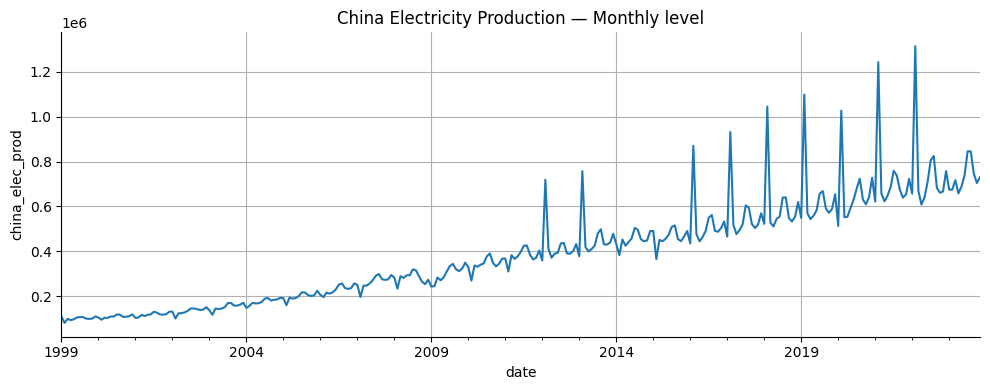

In [35]:
ax = y.plot(title="China Electricity Production — Monthly level")
ax.set_ylabel(y.name)
plt.tight_layout()
# plt.savefig("china_elec_level.png", dpi=200, bbox_inches="tight")
plt.show()


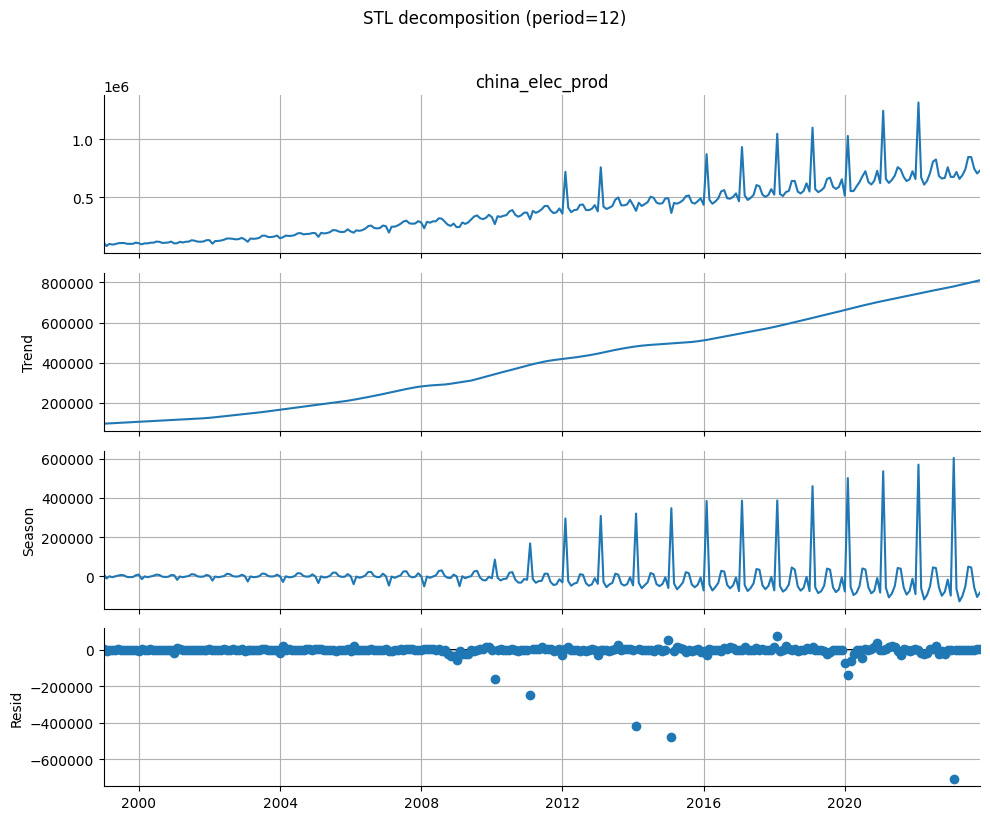

Seasonal strength (heuristic): 0.73


In [36]:
stl = STL(y.dropna(), period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(10, 8)
plt.suptitle("STL decomposition (period=12)", y=1.02)
plt.tight_layout()
# plt.savefig("china_elec_stl.png", dpi=200, bbox_inches="tight")
plt.show()

# Seasonal strength: 0 (no seasonality) .. 1 (very strong seasonality)
seasonal_var  = np.var(stl.seasonal, ddof=1)
remainder_var = np.var(stl.resid,   ddof=1)
seasonal_strength = 1 - remainder_var/(remainder_var + seasonal_var)
print(f"Seasonal strength (heuristic): {seasonal_strength:.2f}")


In [37]:
def adf_kpss_pvals(x):
    x = x.dropna()
    adf_p  = adfuller(x, autolag="AIC")[1]           # H0: unit root
    try:
        kpss_p = kpss(x, regression="c", nlags="auto")[1]  # H0: stationary
    except Exception:
        kpss_p = np.nan
    return adf_p, kpss_p

tests = []
labels = [("Level", y),
          ("Δ (d=1)", y.diff(1)),
          ("∇12 (D=1)", y.diff(12)),
          ("Δ & ∇12", y.diff(1).diff(12))]

for name, series in labels:
    adf_p, kpss_p = adf_kpss_pvals(series)
    tests.append((name, adf_p, kpss_p))

pd.DataFrame(tests, columns=["Series","ADF p (H0: unit root)","KPSS p (H0: stationary)"]).round(4)


,Series,ADF p (H0: unit root),KPSS p (H0: stationary)
0,Level,0.9894,0.01
1,Δ (d=1),0.0000,0.10
2,∇12 (D=1),0.0000,0.10
3,Δ & ∇12,0.0000,0.10


In [38]:
from statsmodels.tsa.stattools import acf as sm_acf
acf_d1 = sm_acf(y.diff(1).dropna(), nlags=24, fft=True)
print("lag-12 ACF after d=1:", float(acf_d1[12]))


lag-12 ACF after d=1: 0.7595223145689292


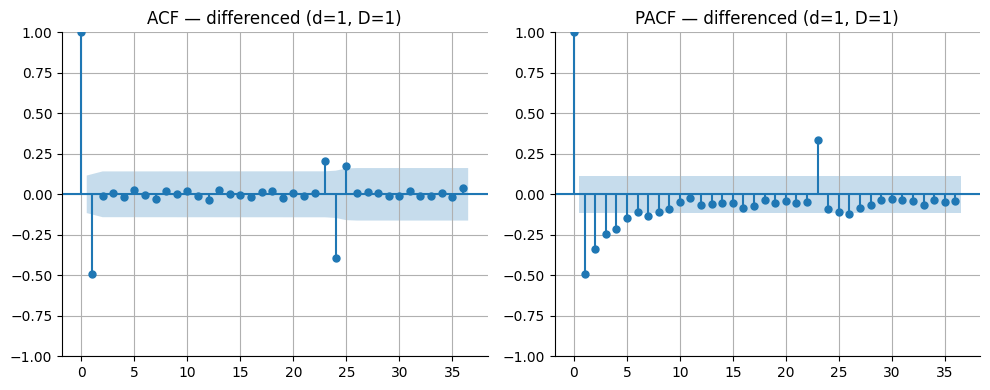

In [39]:
s = 12
y_id = y.diff(1).diff(s).dropna()

fig, ax = plt.subplots(1, 2, figsize=(10,4))
plot_acf(y_id,  lags=36, ax=ax[0]); ax[0].set_title("ACF — differenced (d=1, D=1)")
plot_pacf(y_id, lags=36, ax=ax[1], method="ywm"); ax[1].set_title("PACF — differenced (d=1, D=1)")
plt.tight_layout()
# plt.savefig("china_elec_id_acf_pacf.png", dpi=200, bbox_inches="tight")
plt.show()


In [40]:
def sarima_grid_search(series, order_grid, seasonal_grid, d=1, D=1, s=12):
    rows, models = [], {}
    for p,q in order_grid:
        for P,Q in seasonal_grid:
            try:
                res = SARIMAX(series,
                              order=(p,d,q),
                              seasonal_order=(P,D,Q,s),
                              enforce_stationarity=False,
                              enforce_invertibility=False
                             ).fit(disp=False)
                rows.append({"p":p,"d":d,"q":q,"P":P,"D":D,"Q":Q,
                             "AIC":res.aic, "BIC":res.bic})
                models[(p,q,P,Q)] = res
            except Exception:
                pass
    table = pd.DataFrame(rows).sort_values(["AIC","BIC"]).reset_index(drop=True)
    return table, models

order_grid    = [(0,0),(1,0),(1,1),(2,0),(2,1),(2,2),(3,0),(3,1)]
seasonal_grid = [(0,0),(1,0),(0,1),(1,1)]

sel_table, models = sarima_grid_search(y, order_grid, seasonal_grid, d=1, D=1, s=12)
sel_table.head(8)


,p,d,q,P,D,Q,AIC,BIC
0,2,1,2,1,1,1,6772.470536,6797.685367
1,3,1,1,1,1,1,6777.759079,6802.973911
2,2,1,2,0,1,1,6779.716860,6801.329573
3,3,1,1,1,1,0,6797.854634,6819.467347
4,1,1,1,1,1,1,6798.776746,6816.805756
5,2,1,1,1,1,1,6800.526458,6822.161271
6,1,1,1,0,1,1,6804.497751,6818.920959
7,2,1,1,0,1,1,6806.373481,6824.402491


In [41]:
best_row = sel_table.iloc[0]
bp,bd,bq,bP,bD,bQ = map(int, [best_row[c] for c in ["p","d","q","P","D","Q"]])
best = models[(bp,bq,bP,bQ)]
print(best.summary())


                                      SARIMAX Results                                       
Dep. Variable:                      china_elec_prod   No. Observations:                  299
Model:             SARIMAX(2, 1, 2)x(1, 1, [1], 12)   Log Likelihood               -3379.235
Date:                              Tue, 10 Feb 2026   AIC                           6772.471
Time:                                      14:41:59   BIC                           6797.685
Sample:                                  01-01-1999   HQIC                          6782.595
                                       - 11-01-2023                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8446      1.389     -0.608      0.543      -3.568       1.878
ar.L2         -0.02

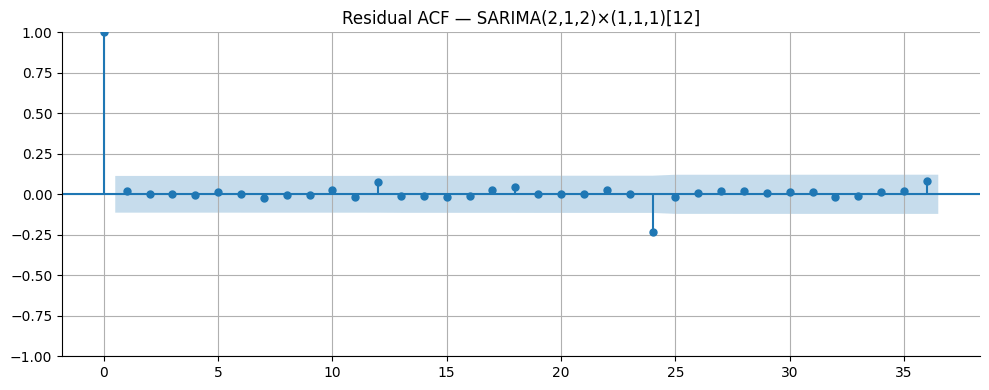

,lb_stat,lb_pvalue
12,2.738689,0.997125
24,22.124460,0.571838
36,25.391874,0.906397


In [42]:
resid = best.resid.dropna()

# Residual ACF
fig, ax = plt.subplots()
plot_acf(resid, lags=36, ax=ax)
ax.set_title(f"Residual ACF — SARIMA({bp},{bd},{bq})×({bP},{bD},{bQ})[12]")
plt.tight_layout()
# plt.savefig("china_elec_resid_acf.png", dpi=200, bbox_inches="tight")
plt.show()

# Ljung–Box p-values at seasonal horizons
lb = acorr_ljungbox(resid, lags=[12,24,36], return_df=True)
lb


Test MAE: 54288.884 | RMSE: 124459.884


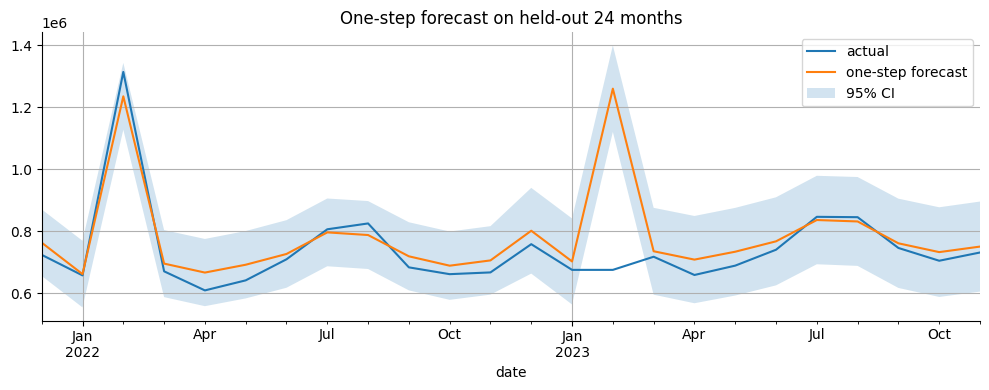

In [43]:
h = 24
train, test = y.iloc[:-h], y.iloc[-h:]

m_train = SARIMAX(train,
                  order=(bp,bd,bq),
                  seasonal_order=(bP,bD,bQ,12),
                  enforce_stationarity=False,
                  enforce_invertibility=False
                 ).fit(disp=False)

pred      = m_train.get_prediction(start=test.index[0], end=test.index[-1], dynamic=False)
pred_mean = pred.predicted_mean
pred_ci   = pred.conf_int()

mae  = (pred_mean - test).abs().mean()
rmse = np.sqrt(((pred_mean - test)**2).mean())
print(f"Test MAE: {mae:.3f} | RMSE: {rmse:.3f}")

fig, ax = plt.subplots()
test.plot(ax=ax, label="actual")
pred_mean.plot(ax=ax, label="one-step forecast")
ax.fill_between(pred_ci.index,
                pred_ci.iloc[:,0].astype(float).values,
                pred_ci.iloc[:,1].astype(float).values,
                alpha=0.2, label="95% CI")
ax.set_title("One-step forecast on held-out 24 months")
ax.legend()
plt.tight_layout()
# plt.savefig("china_elec_onestep_test.png", dpi=200, bbox_inches="tight")
plt.show()


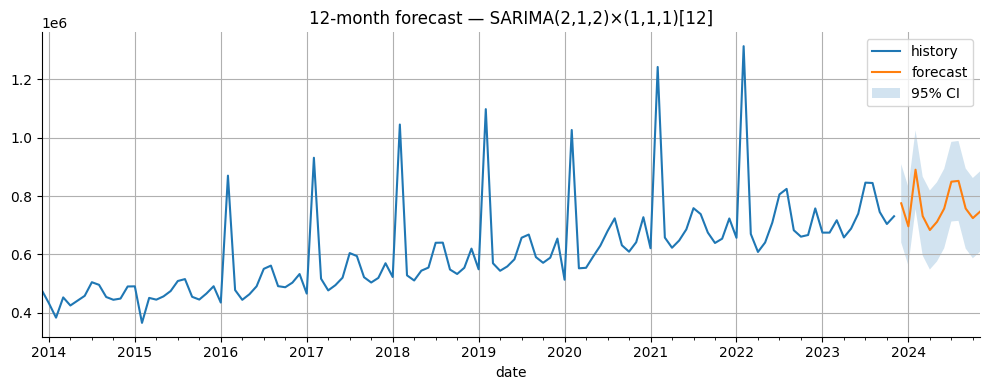

In [44]:
final = SARIMAX(y,
                order=(bp,bd,bq),
                seasonal_order=(bP,bD,bQ,12),
                enforce_stationarity=False,
                enforce_invertibility=False
               ).fit(disp=False)

fc   = final.get_forecast(steps=12)
fc_mu, fc_ci = fc.predicted_mean, fc.conf_int()

fig, ax = plt.subplots()
y.tail(120).plot(ax=ax, label="history")
fc_mu.plot(ax=ax, label="forecast")
ax.fill_between(fc_ci.index,
                fc_ci.iloc[:,0].astype(float).values,
                fc_ci.iloc[:,1].astype(float).values,
                alpha=0.2, label="95% CI")
ax.set_title(f"12-month forecast — SARIMA({bp},{bd},{bq})×({bP},{bD},{bQ})[12]")
ax.legend()
plt.tight_layout()
# plt.savefig("china_elec_forecast_12m.png", dpi=200, bbox_inches="tight")
plt.show()
